# The distant dipolar field

The magnetisation of a liquid sample is a source of magnetic field at every
point of the sample. In a spherical sample at equilibrium that field is
nothing (the Lorentz field and the demagnetising field cancel), which is why
it is usually forgotten; but a pulse sequence with gradients writes a helix
of magnetisation into the sample, and a helix has a field, the *distant
dipolar field* (DDF, or demagnetising field). It is weak, of the order of
10 s⁻¹ in angular frequency for water at 9.4 T, and it depends on the
state, so the equation of motion is nonlinear, as for
[radiation damping](radiation-damping.ipynb). Its effects are nevertheless
visible: the CRAZED experiment (Warren and co-workers, Science 262, 2005
(1993)) detects a signal that grows from nothing, and the multiple spin
echoes of Deville, Bernier and Delrieux (Phys. Rev. B 19, 5666 (1979)) and
Bowtell, Bowley and Glover (J. Magn. Reson. 88, 643 (1990)) appear under a
read gradient. This guide covers `spynach.dipolar_field`, the mean-field
generator of a spin system in its own dipolar field, and its use inside
[pulse programs](pulse-programs.ipynb), where it is computed on the lattice
of Fourier modes of explicit mode: no spatial grid anywhere. Nothing here
has a Spinach counterpart. The companion notebook is
[`notebooks/distant-dipolar-field.ipynb`](distant-dipolar-field.ipynb)
([interactive figures on nbviewer](https://nbviewer.org/github/ajerschow/spynach/blob/main/docs/notebooks/distant-dipolar-field.ipynb)).

Every Python block is executed by `tests/docs/`, in order and in one
namespace. The demagnetising shift, the CRAZED build-up and the multiple
spin echoes also run in the browser playground
([`try.html#ex-ddf-shift`](https://ajerschow.github.io/spynach/try.html#ex-ddf-shift),
[`#ex-ddf-crazed`](https://ajerschow.github.io/spynach/try.html#ex-ddf-crazed),
[`#ex-ddf-echoes`](https://ajerschow.github.io/spynach/try.html#ex-ddf-echoes)).

*Generated from [`docs/distant-dipolar-field.md`](../distant-dipolar-field.md) by `docs/build_notebooks.py`; edit the Markdown guide, not this notebook.*

Run the cells in order: later cells use names defined by earlier ones. The saved outputs come from running the notebook top to bottom; plotting cells need Plotly (`pip install -e ".[docs]"`).

## Contents

1. [The field and its conventions](#The-field-and-its-conventions)
2. [The demagnetising shift without gradients](#The-demagnetising-shift-without-gradients)
3. [The CRAZED build-up](#The-CRAZED-build-up)
4. [Multiple spin echoes under a read gradient](#Multiple-spin-echoes-under-a-read-gradient)
5. [Several spins: concentrations and the transverse term](#Several-spins:-concentrations-and-the-transverse-term)
6. [Where it is computed: the Fourier-mode lattice](#Where-it-is-computed:-the-Fourier-mode-lattice)
7. [What is checked, and the limits](#What-is-checked,-and-the-limits)

## The field and its conventions

When the magnetisation varies along one direction `s` only, as it does after
gradients on one axis, the dipolar field at a point depends on the
magnetisation at that point alone (Deville et al. 1979). In the rotating
frame, keeping the secular part,

    B_d(s) = μ0 Δ [ M(s)/3 − M_z(s) ẑ ],      Δ = (3 cos²θ − 1)/2,

with `θ` the angle between `s` and `B0`. A helix along `B0` therefore acts
like a stack of thin discs, `−(2/3) μ0 M_z` along `z`; one across `B0` like a
stack of slabs, `+(1/3) μ0 M_z`; and at the magic angle the field vanishes.
The uniform part of the magnetisation is the exception: it sees the Lorentz
field minus the demagnetising field of the sample shape, which for an
axially symmetric sample has the same form with `Δ_shape = (3 N_z − 1)/2` for
the demagnetising factor `N_z` along `B0`: a sphere (`N_z = 1/3`) has no
uniform field, a long cylinder along `B0` has `Δ_shape = −1/2`, a thin disc
across it `+1`, the limits of the modulated modes.

The strength is the dipolar demagnetising time `τ_d = 1/(|γ| μ0 M0)`, about
0.1 s for water at 9.4 T and 300 K (`ddf_time` computes it from the
concentration). Written as a mean-field Hamiltonian for the total spin `F`
of the isotope, with the magnetisation in units of its equilibrium value,

    H_d = −γ F·B_d = sign(γ) (Δ / τ_d) [ (2/3) m_z F_z − (1/3) (m_x F_x + m_y F_y) ].

For a single spin species this is the Bloch equation
`dM_⊥/dt = −γ μ0 Δ M_z ẑ × M_⊥`: the transverse magnetisation precesses at
`Δ m_z / τ_d` about `z`, `M_z` is constant, and the field is purely a
position-dependent phase. The signs are fixed by the demagnetising limit
and checked against a chemical shift in the tests: a long cylinder along
`B0` shifts the line the way a field adding to `B0` does.

In [1]:
import numpy as np
import spynach
from spynach.ddf import DipolarFieldSpec
from spynach.plotting import plot_time_series
from spynach.program import Acquire, Gradient, Program, Pulse, Sample
from spynach.propagation import iserstep

water = spynach.create({"isotopes": ["1H"], "magnet": 9.4}, {"zeeman": {"scalar": [0.0]}})
water = spynach.assume(spynach.basis(water, {"formalism": "sphten-liouv", "approximation": "none"}), "nmr")
H = spynach.hamiltonian(water)
tau_d = spynach.ddf_time(water, "1H", concentration=110.0, temperature=300.0)
print(f"tau_d of water at 9.4 T and 300 K: {tau_d * 1e3:.0f} ms")

tau_d of water at 9.4 T and 300 K: 99 ms


## The demagnetising shift without gradients

Without gradients there is one mode, the uniform magnetisation, and the
field is the shape-dependent demagnetising shift: after a pulse of flip
angle `β` the line sits at `Δ_shape cos β / τ_d` (in rad/s; `Δ_shape = (3 N_z − 1)/2`,
the factor of the uniform mode above) from where it would be in a sphere. `dipolar_field(spin_system, L0, isotope, tau_d, demagnetising=N_z)`
builds the generator `L(t, rho)` for `iserstep`, as `radiation_damping`
does; `.stack(rho)` puts a state into the uniform mode, `.magnetisation`
reads the Fourier coefficients of `m_x`, `m_y`, `m_z` back:

sphere: +0.000 rad/s, formula +0.000
cylinder along B0: -2.514 rad/s, formula -2.514
disc across B0: +5.028 rad/s, formula +5.028


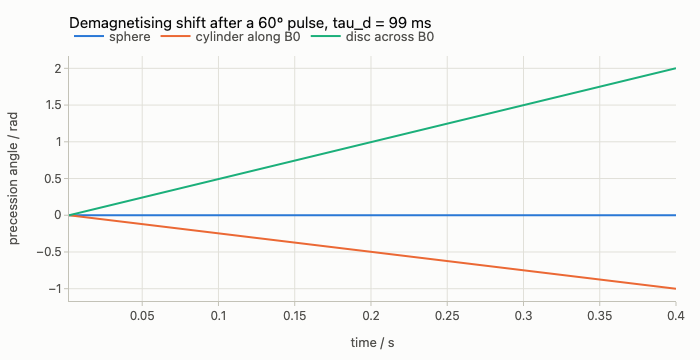

In [2]:
beta, dt, nsteps = np.radians(60), 2e-3, 200
rho_beta = spynach.step(water, spynach.operator(water, "Ly", "1H"), spynach.state(water, "Lz", "1H"), beta)
t = np.arange(1, nsteps + 1) * dt
phases = {}
for shape, n_z in (("sphere", 1 / 3), ("cylinder along B0", 0.0), ("disc across B0", 1.0)):
    ddf = spynach.dipolar_field(water, H + 0j * H, "1H", tau_d, demagnetising=n_z)
    rho = ddf.stack(rho_beta)
    trace = np.zeros(nsteps, dtype=complex)
    for n in range(nsteps):
        rho = iserstep(water, ddf, n * dt, "LG4", rho, dt)
        mx, my, mz = ddf.magnetisation(rho)
        trace[n] = mx[0] + 1j * my[0]
    phases[shape] = np.unwrap(np.angle(trace))
    slope = (phases[shape][-1] - phases[shape][0]) / (t[-1] - t[0])
    print(f"{shape}: {slope:+.3f} rad/s, formula {(3 * n_z - 1) / 2 * np.cos(beta) / tau_d:+.3f}")
plot_time_series(
    t,
    [phases[s] - phases[s][0] for s in phases],
    names=list(phases),
    xlabel="time / s",
    ylabel="precession angle / rad",
    title=f"Demagnetising shift after a {np.degrees(beta):.0f}° pulse, tau_d = {tau_d * 1e3:.0f} ms",
)

## The CRAZED build-up

Two 90° pulses with a gradient between them write a helix of longitudinal
magnetisation, `M_z = −M0 sin(ks)`, next to a helix of transverse
magnetisation, `M_+ = M0 cos(ks)`. A second gradient of `m` times the area
then selects, from the transverse magnetisation, the component at
wavevector `−m k`: nothing for `m ≥ 2`, until the field of the
longitudinal helix winds the transverse one, `M_+(s, t) = M0 cos(ks)
exp(i a sin ks)` with `a = Δ t / τ_d`, whose Fourier component `m` is
`(m/a) J_m(a)`. The signal grows from zero during the acquisition and
peaks after a few `τ_d`.

A `Program` takes the field as `field=DipolarFieldSpec(isotope, tau_d,
...)` and runs it in explicit mode, where every delay, gradient and dwell
is integrated by `iserstep` on the Fourier-mode lattice; `nmodes` is the
number of harmonics kept beyond the modes the gradients reach, and the
angle of the field follows the gradient axis. The sample is a sphere, with no uniform field
(`demagnetising=1/3`, the default), and the closed form above, which gives
the uniform part the field of the modulation, is recovered with
`demagnetising=1.0`, a disc for a helix along `B0`. The comparison is made
on the uniform mode (`output="modes"`): the FID itself also carries the
sinc tail of the helix through the finite sample, about `1/(k0 z_max)` of
its amplitude, a part in a thousand here:

In [3]:
from scipy.special import jv

delta, G, dt, npoints = 20e-6, 2.0, 2e-3, 100
tau_d = 0.1
t = np.arange(npoints) * dt + delta  # the field acts during the second gradient as well


def crazed(m, theta=0.0, **field):
    c, s = np.cos(theta), np.sin(theta)
    return Program(
        [
            Pulse("1H", np.pi / 2),
            Gradient(delta, z=G * c, x=G * s),
            Pulse("1H", np.pi / 2),
            Gradient(delta, z=m * G * c, x=m * G * s),
            Acquire("1H", dt, npoints),
        ],
        mode="explicit",
        field=DipolarFieldSpec("1H", tau_d, nmodes=8, **field),
    )




def uniform(program, spin_system, H):
    modes = program.run(spin_system, H, 0 * H, 0 * H, output="modes")
    return modes.signals[modes.modes == 0][0]


def closed_form(m, a):
    a = np.where(a != 0, a, 1e-300)
    return m / a * jv(m, a)


single = uniform(Program([Pulse("1H", np.pi / 2), Acquire("1H", dt, 1)], mode="explicit"), water, H)[0]
curves, names = [], []
for m in (1, 2, 3):
    fid = uniform(crazed(m, demagnetising=1.0), water, H) / single
    closed = closed_form(m, t / tau_d)
    print(f"m = {m}: largest |signal| {np.abs(fid).max():.3f} of the single-pulse signal, closed form to {np.abs(np.abs(fid) - np.abs(closed)).max():.1e}")
    curves.append(np.abs(fid))
    names.append(f"m = {m}")
    if m == 2:
        curves.append(np.abs(closed))
        names.append("(2/a) J_2(a)")
sphere = uniform(crazed(2), water, H) / single
magic = uniform(crazed(2, theta=np.arccos(1 / np.sqrt(3))), water, H) / single
print(f"sphere: largest |signal| {np.abs(sphere).max():.3f}; at the magic angle {np.abs(magic).max():.1e}")

m = 1: largest |signal| 0.500 of the single-pulse signal, closed form to 8.3e-07
m = 2: largest |signal| 0.352 of the single-pulse signal, closed form to 6.6e-07
m = 3: largest |signal| 0.191 of the single-pulse signal, closed form to 2.7e-07
sphere: largest |signal| 0.380; at the magic angle 5.5e-17


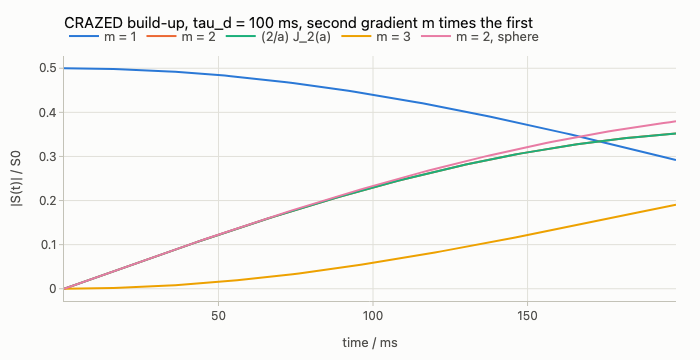

In [4]:
plot_time_series(
    t * 1e3,
    curves + [np.abs(sphere)],
    names=names + ["m = 2, sphere"],
    xlabel="time / ms",
    ylabel="|S(t)| / S0",
    title=f"CRAZED build-up, tau_d = {tau_d * 1e3:.0f} ms, second gradient m times the first",
)

The `m = 1` echo is the ordinary gradient echo at half the single-pulse
signal, and it decays as the field winds it away; `m = 2`, the CRAZED
signal proper, grows linearly as `t / (4 τ_d)` and peaks at `a ≈ 3`.
In the sphere the uniform transverse magnetisation, the signal itself,
makes no field, and the curve differs from the closed form by a few per
cent once the signal is appreciable. The modes behind the signal are
available as `output="modes"`:

In [5]:
modes = crazed(2).run(water, H, 0 * H, 0 * H, output="modes")
strong = np.argsort(np.abs(modes.signals).max(axis=1))[::-1][:4]
for i in sorted(strong, key=lambda i: modes.modes[i]):
    print(f"mode {modes.modes[i]:+d} (k = {modes.modes[i] * modes.k0:.0f} rad/m): largest |signal| {np.abs(modes.signals[i]).max() / abs(single):.3f}, envelope {modes.envelope[i]:.1e}")

mode -4 (k = -42804 rad/m): largest |signal| 0.346, envelope 1.8e-03
mode -3 (k = -32103 rad/m): largest |signal| 0.500, envelope -1.8e-03
mode -1 (k = -10701 rad/m): largest |signal| 0.500, envelope -1.8e-03
mode +0 (k = 0 rad/m): largest |signal| 0.380, envelope 1.0e+00


The helix at `k = ±k0` carries the largest transverse magnetisation and is
dephased by the sample envelope; mode 0 is what the coil sees.

## Multiple spin echoes under a read gradient

With a read gradient on during the acquisition the transverse helix is
wound continuously, and the component at every harmonic of the
longitudinal helix passes through the uniform mode in turn: an echo at
every multiple of the time the read gradient needs to undo the first one,
the `n`-th with amplitude `(n/a) J_n(a)` at its own time. The first is the
gradient echo; the others exist only through the field. Here the read
gradient unwinds one unit per dwell, the first gradient is `m0` units, and
the sample is a cylinder short enough for the echoes to have a shape (the
sinc envelope of its length):

In [6]:
sample = Sample(z_max=5e-3, x_max=2.5e-3)
gamma = water.gammas[0]
dt, npoints, m0, tau_echo = 0.5e-3, 100, 16, 0.02
unit = 2 / (gamma * sample.z_max)  # one unit of gradient area per dwell: k0 z_max = 2
echoes = Program(
    [
        Pulse("1H", np.pi / 2),
        Gradient(1e-3, z=m0 * unit / 1e-3),
        Pulse("1H", np.pi / 2),
        Acquire("1H", dt, npoints, gradient=Gradient(0, z=-unit / dt)),
    ],
    mode="explicit",
    sample=sample,
    field=DipolarFieldSpec("1H", tau_echo, nmodes=8, demagnetising=1.0),
)
fid_echoes = echoes.run(water, H, 0 * H, 0 * H) / single
t_read = np.arange(npoints) * dt
for n in (1, 2, 3, 4, 5, 6):
    i = n * m0
    if i < npoints:
        print(f"echo {n} at {t_read[i] * 1e3:.0f} ms: |S| {np.abs(fid_echoes[i]):.3f}, (n/a) J_n(a) = {abs(closed_form(n, t_read[i] / tau_echo)):.3f}")

echo 1 at 8 ms: |S| 0.483, (n/a) J_n(a) = 0.490
echo 2 at 16 ms: |S| 0.188, (n/a) J_n(a) = 0.190
echo 3 at 24 ms: |S| 0.079, (n/a) J_n(a) = 0.082
echo 4 at 32 ms: |S| 0.032, (n/a) J_n(a) = 0.037
echo 5 at 40 ms: |S| 0.017, (n/a) J_n(a) = 0.018
echo 6 at 48 ms: |S| 0.009, (n/a) J_n(a) = 0.008


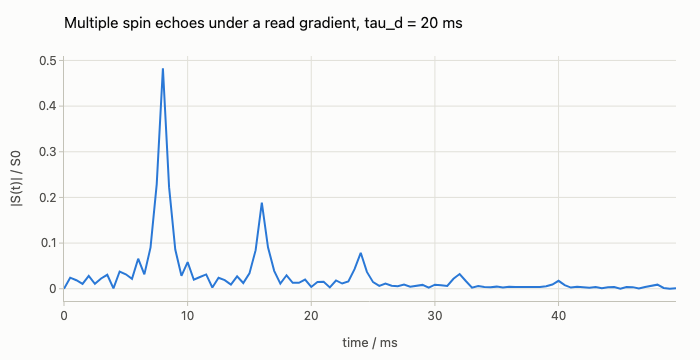

In [7]:
plot_time_series(t_read * 1e3, np.abs(fid_echoes), xlabel="time / ms", ylabel="|S(t)| / S0", title=f"Multiple spin echoes under a read gradient, tau_d = {tau_echo * 1e3:.0f} ms")

`tau_d` is set to 20 ms here, a few times shorter than water's, so that
the later echoes are visible within a short acquisition; the amplitudes at
the echo tops follow the Bessel functions, the sample envelope gives the
echoes their width, and the floor between them is the sinc tail of the
helix itself through the finite sample.

## Several spins: concentrations and the transverse term

The field is read from the magnetisation of every spin of the isotope,
weighted by `weights`, the relative number densities (a solvent and a
solute), and it acts on every spin alike. The transverse term of the field
matters when the spins have different histories: the torque on a spin from
the transverse part of the field goes through that spin's own longitudinal
magnetisation, so a spin precesses at `(2/3)` of the total longitudinal
helix plus `(1/3)` of its own. Two protons whose longitudinal helices are
made antiparallel (a selective 180° pulse on the second before the second
90°) show both effects: with equal weights the total helix vanishes and so
does the signal, and with weights `(1, 3)` the two spins precess at
`[(2/3)σ ± 1/3] t / τ_d` with `σ = (w1 − w2)/(w1 + w2)`, a closed form
while the transverse magnetisations stay parallel:

In [8]:
pair = spynach.create({"isotopes": ["1H", "1H"], "magnet": 9.4}, {"zeeman": {"scalar": [0.0, 0.0]}})
pair = spynach.assume(spynach.basis(pair, {"formalism": "sphten-liouv", "approximation": "none"}), "nmr")
H2 = spynach.hamiltonian(pair)
n_short = 12
t_short = np.arange(n_short) * 1e-3 + delta


def reversed_pair(weights):
    program = Program(
        [
            Pulse("1H", np.pi / 2),
            Gradient(delta, z=G),
            Pulse([1], np.pi),
            Pulse("1H", np.pi / 2),
            Gradient(delta, z=2 * G),
            Acquire("1H", 1e-3, n_short),
        ],
        mode="explicit",
        field=DipolarFieldSpec("1H", tau_d, nmodes=8, demagnetising=1.0, weights=weights),
    )
    return program.run(pair, H2, 0 * H2, 0 * H2)


single_pair = Program([Pulse("1H", np.pi / 2), Acquire("1H", 1e-3, 1)], mode="explicit").run(pair, H2, 0 * H2, 0 * H2)[0]
print(f"equal weights: largest |signal| {np.abs(reversed_pair([1.0, 1.0])).max() / abs(single_pair):.1e}")
sigma = (1 - 3) / (1 + 3)
a1, a2 = (2 / 3 * sigma + 1 / 3) * t_short / tau_d, (2 / 3 * sigma - 1 / 3) * t_short / tau_d
closed = (closed_form(2, a1) + closed_form(2, a2)) / 2
fid_13 = reversed_pair([1.0, 3.0]) / single_pair
print(f"weights (1, 3): |signal| after {t_short[-1] * 1e3:.0f} ms {np.abs(fid_13[-1]):.5f}, closed form {abs(closed[-1]):.5f}")

equal weights: largest |signal| 1.1e-05
weights (1, 3): |signal| after 11 ms 0.00917, closed form 0.00918


## Where it is computed: the Fourier-mode lattice

Explicit mode holds the state as one vector per wavevector `n k0` along
the gradient axis (the [pulse programs](pulse-programs.ipynb#The-explicit-cycle-on-the-Fourier-mode-lattice)
guide), and the field is the only place where modes talk to each other: a
product in position is a convolution in the mode index,

    dρ_n/dt = −i L0 ρ_n − i Σ_m L_d(m) ρ_{n−m},

with `L_d(m)` the commutation superoperator of `H_d` built from the Fourier
coefficients of the magnetisation in mode `m`. Three fixed superoperators
(`F_x`, `F_y`, `F_z` of the isotope) and the coefficients read from the
state are all it takes; `DipolarField.__call__` assembles the block
generator `kron(I, L0) + Σ_m kron(S_m, L_d(m))` (plus the diffusion damping
`D (n k0)²` of every mode) that `iserstep` integrates, so every method of
the [radiation damping](radiation-damping.ipynb#Choosing-a-method) guide and
its convergence story apply. The lattice is extended by `nmodes` harmonics
beyond what the gradients reach; the field generates them one neighbour at
a time with a factor of order `t/τ_d`, so their amplitude falls like
`J_n(t/τ_d)` and `nmodes` of 8 is converged to machine precision for a few
`τ_d`. A grid of positions along one pitch of the helix carries the same
information (the tests compare the two), but on the lattice a gradient is
a relabelling, acquisition is one coefficient, and the only cost that grows
is the convolution over a few dozen modes.

## What is checked, and the limits

`tests/unit/test_ddf.py` checks: the demagnetising shift of the uniform mode
for three shapes, its sign against a chemical shift and the constancy of
`m_z`; the CRAZED build-up for second gradients of one, two and three units
along `B0`, across it and at the magic angle against the Bessel closed form
to 1e-5, with the convergence in `nmodes`; the lattice against the local
field on a grid of 32 positions for a J-coupled pair with different shifts
and T1/T2 relaxation in a sphere, to 1e-9; the conjugate symmetry of the
modes, T1 recovery in the uniform mode only, T2 on the helix; the
concentration weights against the two-spin closed form and the
equal-weights cancellation; `ddf_time` for water; and the input checks.
`tests/unit/test_program.py` pins the lattice itself to the pathway runner.

The limits, by construction: one modulation axis, so all gradients of a
program are collinear; one isotope produces and feels the field (the field
of a second isotope would need its own rotating frame); the secular form;
the uniform mode by the demagnetising factor of an axially symmetric
sample only; the field is sampled at the integrator's step (`timestep`,
the acquisition dwell by default), with the linear part exact, so the
spins should be near resonance or the step short against the offsets; and
during a gradient pulse the field acts at the wavevectors before the
shift, so gradient pulses should be short against `τ_d`. `Evolve` and
`Refocus` are not available with a field (the build-up is read during the
acquisition). Thermalisation needs no special case: Spinach-style
relaxation drives through the unit state, which only the uniform mode
carries.